# MY2027 Price List & Configurator Data Quality Checks
**Fictional data** (Northline Motors is not a real brand). The registration-tax scale is illustrative, not the Greek law in force.

Question: *Before the MY2027 prices go live, does the pricing database used by the configurator and invoicing match the approved price list?*

In [1]:
import pandas as pd, numpy as np, math, sqlite3
import matplotlib.pyplot as plt
pd.set_option('display.width', 160)
D = ''
v26  = pd.read_csv(D+'variants_my2026.csv')
app  = pd.read_csv(D+'price_list_my2027_approved.csv')
o26  = pd.read_csv(D+'options_my2026.csv')
o27  = pd.read_csv(D+'options_my2027_approved.csv')
pk   = pd.read_csv(D+'packages_my2027.csv')
exp  = pd.read_csv(D+'configurator_export_my2027.csv')
print('MY2026 variants:', len(v26), '| approved MY2027 variants:', len(app), '| approved options:', len(o27), '| packages:', len(pk), '| export rows:', len(exp))
exp['item_type'].value_counts()

MY2026 variants: 24 | approved MY2027 variants: 24 | approved options: 16 | packages: 3 | export rows: 45


item_type
VARIANT    25
OPTION     17
PACKAGE     3
Name: count, dtype: int64

## 1. Pricing rules (parameters)
Retail price = net price × (1 + VAT 24%) + registration tax, rounded **up** to the next €10. Registration tax = net price × band rate × CO2 multiplier (EV = 0).

In [2]:
VAT = 0.24
TAX_BANDS = [(0, 20000, 0.04), (20000.01, 30000, 0.08), (30000.01, 45000, 0.16), (45000.01, 1e9, 0.24)]
CO2_MULT  = [(0, 0, 0.0), (1, 50, 0.25), (51, 120, 1.0), (121, 160, 1.25), (161, 999, 1.5)]
def reg_tax(net, co2):
    rate = next(r for lo, hi, r in TAX_BANDS if lo <= net <= hi)
    mult = next(m for lo, hi, m in CO2_MULT if lo <= co2 <= hi)
    return round(net * rate * mult, 2)
def retail(net, co2):
    return int(math.ceil((net * (1 + VAT) + reg_tax(net, co2)) / 10) * 10)
# the approved list must follow its own rules
app['check_retail'] = [retail(n, c) for n, c in zip(app.net_price_my2027, app.co2_g_km)]
print('Approved rows that break the pricing rule:', (app.check_retail != app.retail_price_my2027).sum())

Approved rows that break the pricing rule: 0


## 2. MY2026 → MY2027 price change log

In [3]:
chg = app.merge(v26[['variant_code','net_price_my2026']], on='variant_code', how='outer', indicator=True)
chg['status'] = chg['_merge'].map({'both':'PRICE UPDATE','left_only':'NEW VARIANT','right_only':'DISCONTINUED'})
chg['change_pct'] = (chg.net_price_my2027 / chg.net_price_my2026 - 1) * 100
chg_log = chg[['variant_code','status','net_price_my2026','net_price_my2027','change_pct','retail_price_my2027']].sort_values('variant_code')
chg_log.to_csv('price_change_log.csv', index=False)
print(chg_log.status.value_counts().to_string())
print('\nAverage net change by fuel (updated variants):')
print(chg.merge(v26[['variant_code','fuel']], on='variant_code', suffixes=('','_26')).query("status=='PRICE UPDATE'").groupby('fuel').change_pct.agg(['mean','min','max']).round(2))

status
PRICE UPDATE    23
NEW VARIANT      1
DISCONTINUED     1

Average net change by fuel (updated variants):
        mean   min   max
fuel                    
Diesel   2.0  1.99  2.01
EV       0.0  0.00  0.00
PHEV     3.0  2.99  3.01
Petrol   2.0  1.98  2.01


## 3. Automated checks: configurator export vs approved list
Each check returns the rows that fail. All failures go into one issue log.

In [4]:
issues = []
def log(check, df, detail):
    for _, r in df.iterrows():
        issues.append({'check': check, 'item_type': r.get('item_type','VARIANT'), 'code': r['code'] if 'code' in r else r['variant_code'], 'detail': detail(r)})
    print(f'{check:<40} {len(df):>2} issue(s)')

ev  = exp[exp.item_type=='VARIANT']
eo  = exp[exp.item_type=='OPTION']
ep  = exp[exp.item_type=='PACKAGE']

# C01 approved variant missing from export
log('C01 Variant missing in export', app[~app.variant_code.isin(ev.code)], lambda r: f"approved net {r.net_price_my2027}, not loaded")
# C02 variant in export but not approved (e.g. discontinued)
log('C02 Variant not in approved list', ev[~ev.code.isin(app.variant_code)], lambda r: f"still ACTIVE at net {r.net_price}")
# C03 duplicate codes
dup = exp[exp.duplicated(['item_type','code'], keep='first')]
log('C03 Duplicate code', dup, lambda r: 'row appears more than once')
# C04 net price differs from approved list
m = ev.drop_duplicates(['code']).merge(app, left_on='code', right_on='variant_code')
bad_net = m[m.net_price != m.net_price_my2027]
old = dict(zip(v26.variant_code, v26.net_price_my2026))
log('C04 Variant net price != approved', bad_net, lambda r: f"export {r.net_price} vs approved {r.net_price_my2027}" + (' (still MY2026 price)' if old.get(r.code)==r.net_price else ' (typo?)'))
# C05 retail price does not follow the rule from the export's own net price and CO2
m['rule_retail'] = [retail(n, c) for n, c in zip(m.net_price, m.co2_g_km_x)]
log('C05 Retail != rule (VAT/tax error)', m[(m.retail_price != m.rule_retail) & (m.retail_price % 10 == 0)], lambda r: f"export retail {r.retail_price} vs rule {r.rule_retail}")
# C06 retail not rounded to EUR 10
log('C06 Retail not rounded to 10', exp[exp.retail_price % 10 != 0], lambda r: f"retail {r.retail_price}")
# C07 EV with CO2 > 0 (registration tax charged on an EV)
log('C07 EV with CO2 > 0', ev[(ev.fuel=='EV') & (ev.co2_g_km > 0)], lambda r: f"CO2 {r.co2_g_km} g/km -> tax charged")
# C08 option not in approved option list (discontinued)
log('C08 Option not in approved list', eo[~eo.code.isin(o27.option_code)], lambda r: f"still ACTIVE at net {r.net_price}")
# C09 option net price differs from approved
mo = eo.merge(o27, left_on='code', right_on='option_code', suffixes=('','_app'))
log('C09 Option net price != approved', mo[mo.net_price != mo.net_price_app], lambda r: f"export {r.net_price} vs approved {r.net_price_app}")
# C10 option offered on a model that breaks a rule (EXCLUDES_FUEL)
fuel_of = dict(zip(app.model, app.fuel))
def rule_break(r):
    if isinstance(r.rule, str) and r.rule.startswith('EXCLUDES_FUEL='):
        bad_f = r.rule.split('=')[1]
        return [mdl for mdl in str(r.model).split(';') if fuel_of.get(mdl) == bad_f]
    return []
mo['breaks'] = mo.apply(rule_break, axis=1)
log('C10 Option availability breaks rule', mo[mo.breaks.str.len() > 0], lambda r: f"{r.rule} but offered on {','.join(r.breaks)}")
# C11 package not cheaper than its options
opt_price = dict(zip(o27.option_code, o27.net_price))
ep = ep.merge(pk, left_on='code', right_on='package_code', suffixes=('','_app'))
ep['options_total'] = ep.contents.apply(lambda s: sum(opt_price[c] for c in s.split(';')))
log('C11 Package >= sum of its options', ep[ep.net_price >= ep.options_total], lambda r: f"package {r.net_price} vs options {r.options_total}")
issue_log = pd.DataFrame(issues)
issue_log.to_csv('issue_log.csv', index=False)
print('\nTOTAL ISSUES:', len(issue_log), '| export rows affected:', issue_log.code.nunique())

C01 Variant missing in export             1 issue(s)
C02 Variant not in approved list          1 issue(s)
C03 Duplicate code                        1 issue(s)
C04 Variant net price != approved         2 issue(s)
C05 Retail != rule (VAT/tax error)        2 issue(s)
C06 Retail not rounded to 10              1 issue(s)
C07 EV with CO2 > 0                       1 issue(s)
C08 Option not in approved list           1 issue(s)
C09 Option net price != approved          1 issue(s)
C10 Option availability breaks rule       1 issue(s)
C11 Package >= sum of its options         1 issue(s)

TOTAL ISSUES: 13 | export rows affected: 12


In [5]:
issue_log

,check,item_type,code,detail
0,C01 Variant missing in export,VARIANT,NL3-SPORTPLUS,"approved net 34990, not loaded"
1,C02 Variant not in approved list,VARIANT,NL3-BASE,still ACTIVE at net 28700
2,C03 Duplicate code,VARIANT,NLE1-LUX,row appears more than once
3,C04 Variant net price != approved,VARIANT,NL2-LUX,export 38920 vs approved 39700 (still MY2026 p...
4,C04 Variant net price != approved,VARIANT,NL4-SPORT,export 51810 vs approved 51180 (typo?)
5,C05 Retail != rule (VAT/tax error),VARIANT,NL1-SPORT,export retail 31620 vs rule 34440
6,C05 Retail != rule (VAT/tax error),VARIANT,NL4-SPORT,export retail 81890 vs rule 82900
7,C06 Retail not rounded to 10,VARIANT,NL5-BASE,retail 86337
8,C07 EV with CO2 > 0,VARIANT,NLE1-BASE,CO2 120.0 g/km -> tax charged
9,C08 Option not in approved list,OPTION,OP14,still ACTIVE at net 1350


## 4. Cross-check with SQL (SQLite)
Load the same files into SQLite and run the `.sql` queries. The SQL results must match the Python checks.

In [6]:
con = sqlite3.connect(':memory:')
exp.to_sql('configurator_export', con, index=False); app.to_sql('approved_price_list', con, index=False)
o27.to_sql('approved_options', con, index=False); pk.to_sql('packages', con, index=False)
q = {f: open(f).read() for f in ['01_variant_price_mismatch.sql','02_missing_and_discontinued.sql','03_package_vs_options.sql']}
s1 = pd.read_sql(q['01_variant_price_mismatch.sql'], con); s2 = pd.read_sql(q['02_missing_and_discontinued.sql'], con); s3 = pd.read_sql(q['03_package_vs_options.sql'], con)
print(s1, '\n'); print(s2, '\n'); print(s3)

        code  export_net  approved_net  diff_net  export_retail  approved_retail
0  NL1-SPORT       25700         25700         0          31620            34440
1    NL2-LUX       38920         39700      -780          56050            57170
2  NL4-SPORT       51810         51180       630          81890            81890
3   NL5-BASE       53960         53960         0          86337            86340
4  NLE1-BASE       38500         38500         0          53900            47740 

                  issue           code
0     MISSING_IN_EXPORT  NL3-SPORTPLUS
1  NOT_IN_APPROVED_LIST       NL3-BASE
2        DUPLICATE_CODE       NLE1-LUX 

  package_code     package_name  package_net_in_export  options_net_total  customer_saving
0         PK03      Winter Pack                   1450               1410              -40
1         PK01     Comfort Pack                   1690               2020              330
2         PK02  Technology Pack                   2790               3290        

In [7]:
py_price = set(issue_log[issue_log.check.str.startswith(('C04','C05','C06','C07')) & (issue_log.item_type=='VARIANT')].code)
print('Variant price issues  Python:', sorted(py_price)); print('                      SQL   :', sorted(s1.code))
print('Match:', py_price == set(s1.code))

Variant price issues  Python: ['NL1-SPORT', 'NL2-LUX', 'NL4-SPORT', 'NL5-BASE', 'NLE1-BASE']
                      SQL   : ['NL1-SPORT', 'NL2-LUX', 'NL4-SPORT', 'NL5-BASE', 'NLE1-BASE']
Match: True


## 5. Price ladder and tax share (approved MY2027 list)

In [8]:
ladder = app.pivot(index='model', columns='trim', values='retail_price_my2027').reindex(columns=['BASE','SPORT','LUX'])
ladder['SPORT vs BASE %'] = (ladder.SPORT/ladder.BASE-1)*100; ladder['LUX vs BASE %'] = (ladder.LUX/ladder.BASE-1)*100
app['tax_share_%'] = app.reg_tax / app.retail_price_my2027 * 100
print(ladder.round(1)); print('\nRegistration tax as % of retail price, by fuel:'); print(app.groupby('fuel')['tax_share_%'].agg(['mean','min','max']).round(1))

trim      BASE    SPORT       LUX  SPORT vs BASE %  LUX vs BASE %
model                                                            
NL1    30760.0  34440.0   37520.0             12.0           22.0
NL2    46860.0  52480.0   57170.0             12.0           22.0
NL2D   49070.0  54960.0   59850.0             12.0           22.0
NL3        NaN  47210.0   51430.0              NaN            NaN
NL4    70380.0  81890.0   89200.0             16.4           26.7
NL5    86340.0  96710.0  105330.0             12.0           22.0
NL6    82350.0  92240.0  100470.0             12.0           22.0
NLE1   47740.0  53470.0   58250.0             12.0           22.0

Registration tax as % of retail price, by fuel:
        mean   min   max
fuel                    
Diesel  17.7  13.9  22.5
EV       0.0   0.0   0.0
PHEV     4.6   4.6   4.6
Petrol  14.4   7.5  22.5


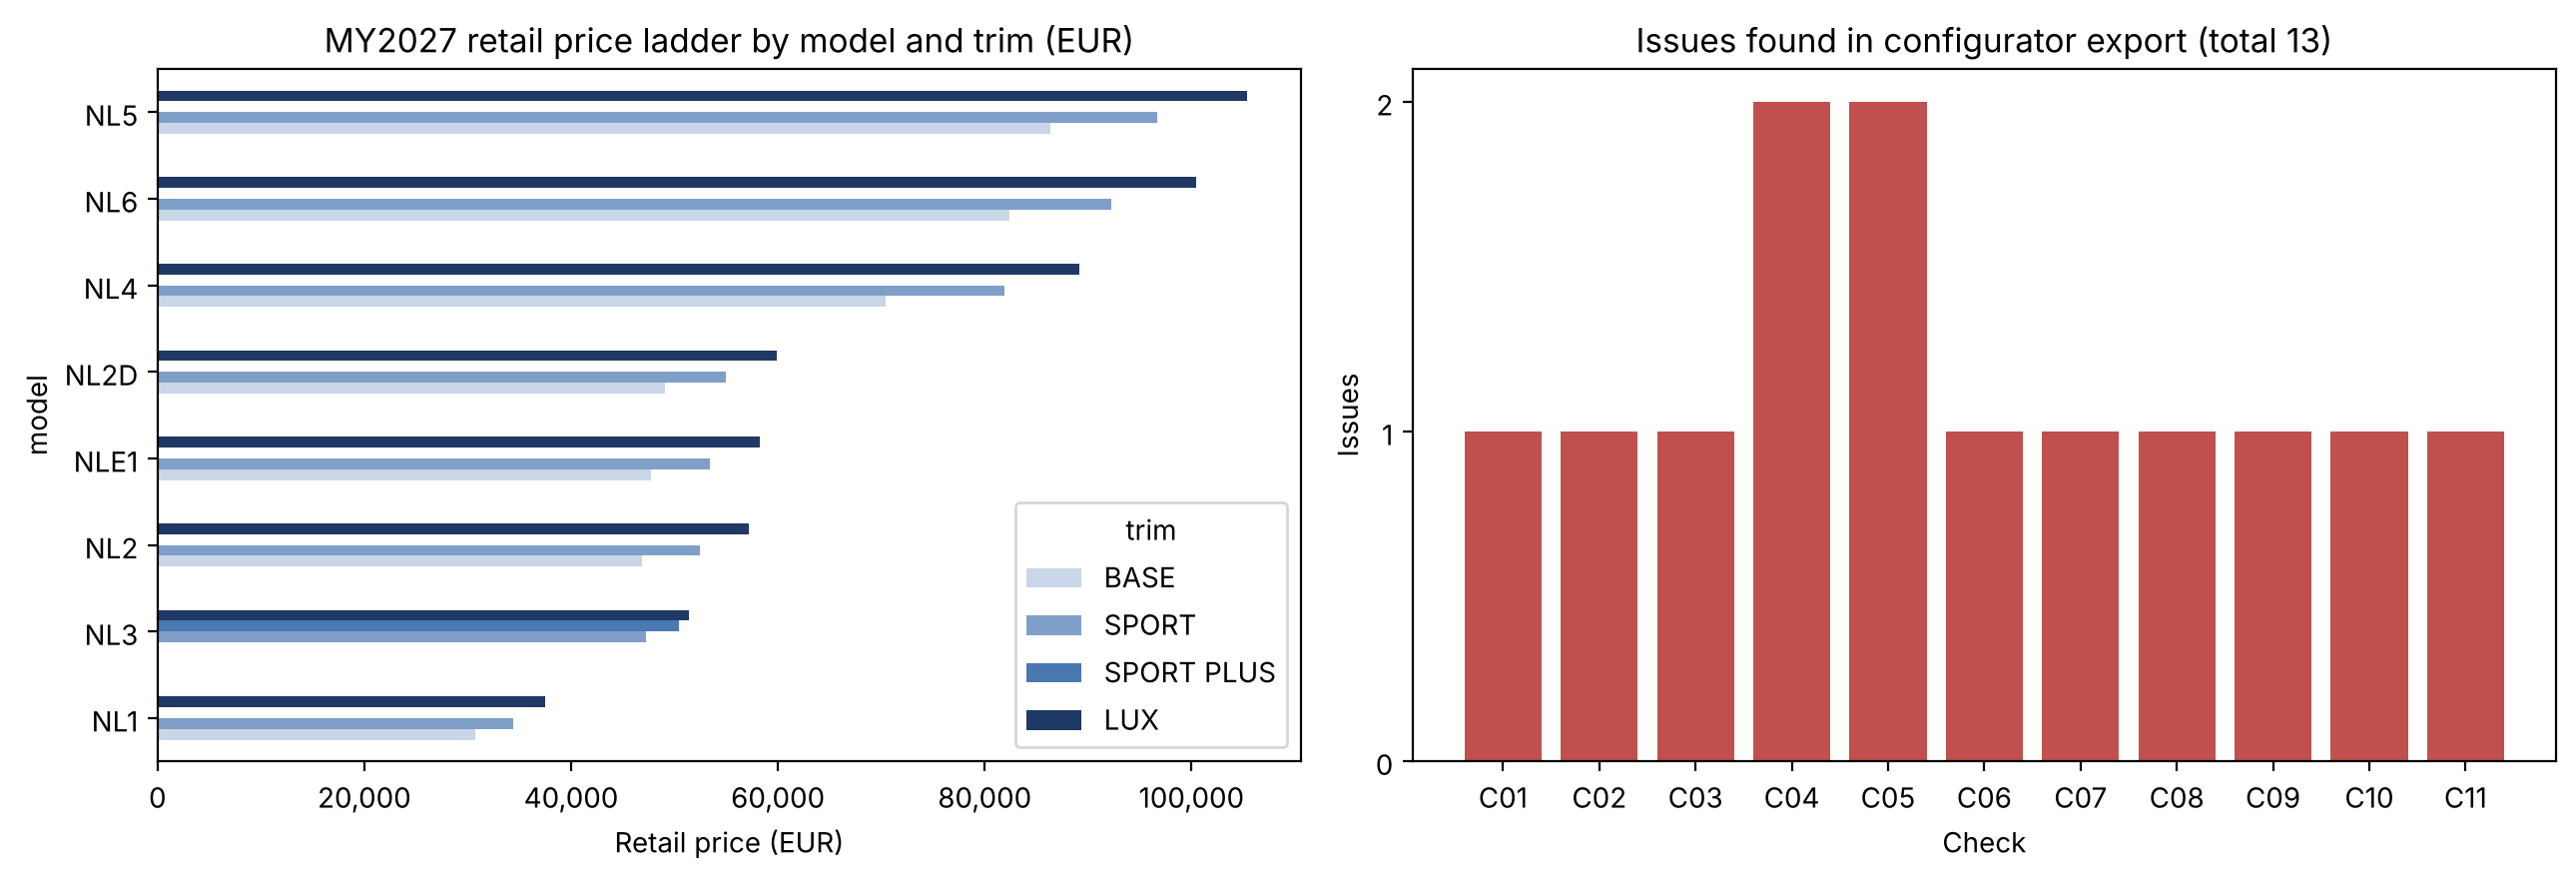

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
lad = app.pivot(index='model', columns='trim', values='retail_price_my2027').reindex(columns=['BASE','SPORT','SPORT PLUS','LUX'])
lad.loc[lad.max(axis=1).sort_values().index].plot(kind='barh', ax=ax[0], color=['#c9d6e8','#7f9fc9','#4a78b0','#1f3864'])
ax[0].set_title('MY2027 retail price ladder by model and trim (EUR)'); ax[0].set_xlabel('Retail price (EUR)')
cnt = issue_log.check.str[:3].value_counts().sort_index()
ax[1].bar(cnt.index, cnt.values, color='#c0504d'); ax[1].set_title(f'Issues found in configurator export (total {len(issue_log)})')
ax[1].set_ylabel('Issues'); ax[1].set_xlabel('Check')
from matplotlib.ticker import MaxNLocator, StrMethodFormatter
ax[1].yaxis.set_major_locator(MaxNLocator(integer=True)); ax[0].xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.tight_layout(); plt.savefig('price_ladder_and_issues.png', dpi=150); plt.show()